In [1]:
!pip -q install transformers datasets accelerate scikit-learn pandas matplotlib

In [2]:
#  Question 2: Beam Search

beam_width = 2

# Time step 1
beam = [
    ("cat", 0.5),
    ("sat", 0.3),
    ("mat", 0.2)
]

beam = sorted(beam, key=lambda x: x[1], reverse=True)[:beam_width]

print("TIME STEP 1")
for sequence, probability in beam:
    print(f"{sequence:15s} Probability = {probability:.3f}")

# Time step 2
probabilities_t2 = {
    "cat": {
        "sat": 0.6,
        "mat": 0.3,
        "</s>": 0.1
    },
    "sat": {
        "cat": 0.2,
        "mat": 0.7,
        "</s>": 0.1
    }
}

expanded = []

for sequence, old_probability in beam:
    for word, conditional_probability in probabilities_t2[sequence].items():
        new_sequence = sequence + " " + word
        cumulative_probability = old_probability * conditional_probability
        expanded.append((new_sequence, cumulative_probability))

print("\nTIME STEP 2 — ALL EXPANDED HYPOTHESES")

for sequence, probability in expanded:
    print(f"{sequence:20s} Probability = {probability:.3f}")

beam = sorted(expanded, key=lambda x: x[1], reverse=True)[:beam_width]

print("\nTOP 2 RETAINED CANDIDATES AT TIME STEP 2")

for sequence, probability in beam:
    print(f"{sequence:20s} Probability = {probability:.3f}")

# Time step 3
probabilities_t3 = {
    "cat sat": {
        "mat": 0.8,
        "</s>": 0.2
    },
    "sat mat": {
        "cat": 0.1,
        "</s>": 0.9
    }
}

expanded = []

for sequence, old_probability in beam:
    for word, conditional_probability in probabilities_t3[sequence].items():
        new_sequence = sequence + " " + word
        cumulative_probability = old_probability * conditional_probability
        expanded.append((new_sequence, cumulative_probability))

print("\nTIME STEP 3 — ALL EXPANDED HYPOTHESES")

for sequence, probability in expanded:
    print(f"{sequence:25s} Probability = {probability:.3f}")

beam = sorted(expanded, key=lambda x: x[1], reverse=True)[:beam_width]

print("\nTOP 2 RETAINED CANDIDATES AT TIME STEP 3")

for sequence, probability in beam:
    print(f"{sequence:25s} Probability = {probability:.3f}")

print("\nFINAL HIGHEST-PROBABILITY SEQUENCE:")
print(beam[0][0])
print("Final probability:", beam[0][1])

TIME STEP 1
cat             Probability = 0.500
sat             Probability = 0.300

TIME STEP 2 — ALL EXPANDED HYPOTHESES
cat sat              Probability = 0.300
cat mat              Probability = 0.150
cat </s>             Probability = 0.050
sat cat              Probability = 0.060
sat mat              Probability = 0.210
sat </s>             Probability = 0.030

TOP 2 RETAINED CANDIDATES AT TIME STEP 2
cat sat              Probability = 0.300
sat mat              Probability = 0.210

TIME STEP 3 — ALL EXPANDED HYPOTHESES
cat sat mat               Probability = 0.240
cat sat </s>              Probability = 0.060
sat mat cat               Probability = 0.021
sat mat </s>              Probability = 0.189

TOP 2 RETAINED CANDIDATES AT TIME STEP 3
cat sat mat               Probability = 0.240
sat mat </s>              Probability = 0.189

FINAL HIGHEST-PROBABILITY SEQUENCE:
cat sat mat
Final probability: 0.24


In [3]:
# ILLM Lab 10 — Question 4: Byte Pair Encoding

from collections import Counter

# Word frequencies from the given corpus
word_frequency = {
    "low": 5,
    "lower": 2,
    "lowest": 3,
    "new": 2,
    "newest": 1,
    "widest": 3
}

# Represent words as characters with an end-of-word marker
vocabulary = {
    word: list(word) + ["</w>"]
    for word in word_frequency
}

def count_pairs(vocabulary, word_frequency):
    pair_counts = Counter()

    for word, symbols in vocabulary.items():
        for i in range(len(symbols) - 1):
            pair = (symbols[i], symbols[i + 1])
            pair_counts[pair] += word_frequency[word]

    return pair_counts

def merge_pair(symbols, best_pair):
    merged_symbols = []
    i = 0

    while i < len(symbols):
        if (
            i < len(symbols) - 1
            and (symbols[i], symbols[i + 1]) == best_pair
        ):
            merged_symbols.append(symbols[i] + symbols[i + 1])
            i += 2
        else:
            merged_symbols.append(symbols[i])
            i += 1

    return merged_symbols

# Perform exactly two merges
merge_rules = []

for step in range(2):
    pair_counts = count_pairs(vocabulary, word_frequency)

    max_frequency = max(pair_counts.values())

    # Alphabetical tie-breaking makes the result reproducible.
    best_pair = sorted(
        pair for pair, count in pair_counts.items()
        if count == max_frequency
    )[0]

    merged_token = best_pair[0] + best_pair[1]

    print(f"\nMerge {step + 1}")
    print("Selected pair:", best_pair)
    print("Frequency:", max_frequency)
    print("New token:", merged_token)

    merge_rules.append((best_pair, merged_token))

    for word in vocabulary:
        vocabulary[word] = merge_pair(
            vocabulary[word], best_pair
        )

print("\nFINAL BPE VOCABULARY")

for word, symbols in vocabulary.items():
    print(
        f"{word:8s} Frequency={word_frequency[word]} "
        f"Tokens={' '.join(symbols)}"
    )

print("\nMERGE RULES")
for i, (pair, token) in enumerate(merge_rules, start=1):
    print(f"{i}. {pair[0]} + {pair[1]} -> {token}")


Merge 1
Selected pair: ('l', 'o')
Frequency: 10
New token: lo

Merge 2
Selected pair: ('lo', 'w')
Frequency: 10
New token: low

FINAL BPE VOCABULARY
low      Frequency=5 Tokens=low </w>
lower    Frequency=2 Tokens=low e r </w>
lowest   Frequency=3 Tokens=low e s t </w>
new      Frequency=2 Tokens=n e w </w>
newest   Frequency=1 Tokens=n e w e s t </w>
widest   Frequency=3 Tokens=w i d e s t </w>

MERGE RULES
1. l + o -> lo
2. lo + w -> low


In [4]:
# ILLM Lab 10 — Question 5: TF-IDF

import math
import pandas as pd

documents = {
    "D1": {
        "text": "machine learning is useful",
        "class": "Technology"
    },
    "D2": {
        "text": "machine learning is powerful",
        "class": "Technology"
    },
    "D3": {
        "text": "learning language is useful",
        "class": "Language"
    },
    "D4": {
        "text": "language processing is useful",
        "class": "Language"
    }
}

# Tokenize the documents
tokens = {
    doc_id: info["text"].lower().split()
    for doc_id, info in documents.items()
}

# Construct vocabulary
vocabulary = sorted(
    set(word for words in tokens.values() for word in words)
)

N = len(documents)

# Document frequency
df = {
    word: sum(word in words for words in tokens.values())
    for word in vocabulary
}

# Calculate IDF
idf = {
    word: math.log10(N / df[word])
    for word in vocabulary
}

# Calculate TF-IDF matrix using raw term frequency
tfidf_matrix = pd.DataFrame(
    0.0,
    index=documents.keys(),
    columns=vocabulary
)

for doc_id, words in tokens.items():
    for word in vocabulary:
        tf = words.count(word)
        tfidf_matrix.loc[doc_id, word] = tf * idf[word]

print("VOCABULARY:")
print(vocabulary)

print("\nDOCUMENT FREQUENCY AND IDF:")
idf_table = pd.DataFrame({
    "Document Frequency": df,
    "IDF": idf
})
display(idf_table.round(4))

print("\nTF-IDF MATRIX:")
display(tfidf_matrix.round(4))

VOCABULARY:
['is', 'language', 'learning', 'machine', 'powerful', 'processing', 'useful']

DOCUMENT FREQUENCY AND IDF:


,Document Frequency,IDF
is,4,0.0000
language,2,0.3010
learning,3,0.1249
machine,2,0.3010
powerful,1,0.6021
processing,1,0.6021
useful,3,0.1249



TF-IDF MATRIX:


,is,language,learning,machine,powerful,processing,useful
D1,0.0,0.000,0.1249,0.301,0.0000,0.0000,0.1249
D2,0.0,0.000,0.1249,0.301,0.6021,0.0000,0.0000
D3,0.0,0.301,0.1249,0.000,0.0000,0.0000,0.1249
D4,0.0,0.301,0.0000,0.000,0.0000,0.6021,0.1249


In [5]:
# Class-wise TF-IDF representation

class_labels = {
    doc_id: info["class"]
    for doc_id, info in documents.items()
}

tfidf_with_class = tfidf_matrix.copy()
tfidf_with_class["Class"] = pd.Series(class_labels)

class_representations = (
    tfidf_with_class
    .groupby("Class")
    .mean(numeric_only=True)
)

print("CLASS REPRESENTATIONS")
display(class_representations.round(4))

CLASS REPRESENTATIONS


,is,language,learning,machine,powerful,processing,useful
Class,,,,,,,
Language,0.0,0.301,0.0625,0.000,0.000,0.301,0.1249
Technology,0.0,0.000,0.1249,0.301,0.301,0.000,0.0625


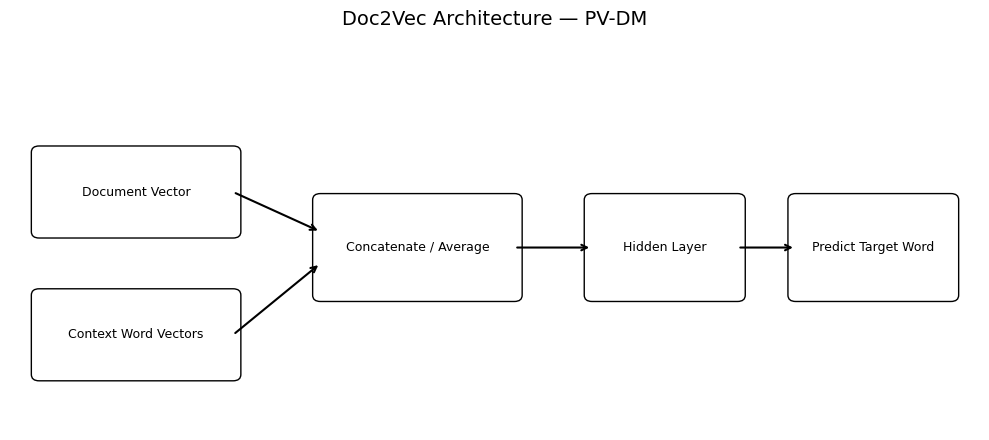

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

boxes = [
    (0.3, 2.5, 2.0, 1.0, "Document Vector"),
    (0.3, 0.7, 2.0, 1.0, "Context Word Vectors"),
    (3.2, 1.7, 2.0, 1.2, "Concatenate / Average"),
    (6.0, 1.7, 1.5, 1.2, "Hidden Layer"),
    (8.1, 1.7, 1.6, 1.2, "Predict Target Word")
]

for x, y, w, h, label in boxes:
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(
        x + w/2, y + h/2, label,
        ha="center", va="center",
        fontsize=9
    )

arrows = [
    ((2.3, 3.0), (3.2, 2.5)),
    ((2.3, 1.2), (3.2, 2.1)),
    ((5.2, 2.3), (6.0, 2.3)),
    ((7.5, 2.3), (8.1, 2.3))
]

for start, end in arrows:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(arrowstyle="->", linewidth=1.5)
    )

ax.set_title("Doc2Vec Architecture — PV-DM", fontsize=14)

plt.tight_layout()
plt.show()

In [8]:
!pip -q install datasets transformers accelerate scikit-learn pandas matplotlib

In [9]:
from datasets import load_dataset

try:
    dataset = load_dataset(
        "ai4bharat/IndicCorpV2",
        streaming=True
    )

    print("Dataset loaded!")
    print(dataset)

except Exception as e:
    print("Dataset loading needs adjustment.")
    print(e)

README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

Dataset loaded!
IterableDatasetDict({
    asm_Beng: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    ben_Beng: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    brx_Deva: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    doi_Deva: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    gom_Deva: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    guj_Gujr: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    hin_Deva: IterableDataset({
        features: Unknown,
        num_shards: 3
    })
    kan_Knda: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    kas_Arab: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    mai_Deva: IterableDataset({
        features: Unknown,
        num_shards: 1
    })
    mal_Mlym: IterableDataset({
        features: Unknown,
        num_shards: 1
 

In [10]:
#  Inspect IndicCorpV2 dataset

print("Available language groups:")
print(list(dataset.keys()))

# Inspect the first record from one language
first_language = list(dataset.keys())[0]

print("\nLanguage:", first_language)

first_record = next(iter(dataset[first_language]))

print("\nFirst record:")
print(first_record)

print("\nRecord type:", type(first_record))

Available language groups:
['asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva', 'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'kas_Arab', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab', 'khasi', 'santhali']

Language: asm_Beng

First record:
{'text': 'ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে বহা জুৱাৰ আড্ডাত শুকুৰবাৰে অৰ্থাৎ ১৯ এপ্ৰিলৰ নিশা প্ৰাক্তন সেনা জোৱানজনে গুলী ফুটাই সন্ত্ৰাসৰ সৃষ্টি কৰে। বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত জুৱাৰীৰ পৰা ধন লুটাৰ স্বাৰ্থতে ধৃত প্ৰাক্তন সেনা জোৱান মোহন কছাৰীয়ে গুলী ফুটাই সন্ত্ৰাস সৃষ্টি কৰে।'}

Record type: <class 'dict'>


In [20]:
# Corrected Batch 7: Collect up to 1000 unique sentences per language

import re
import pandas as pd
from tqdm.auto import tqdm

SAMPLES_PER_LANGUAGE = 1000
all_sentences = []

for lang in tqdm(list(dataset.keys()), desc="Processing languages"):

    unique_sentences = set()
    language_samples = []

    for record in dataset[lang]:
        text = record.get("text", "")

        if not isinstance(text, str) or not text.strip():
            continue

        # Split at sentence-ending punctuation, even without whitespace
        sentences = re.split(r"(?<=[.!?।॥])\s*", text.strip())

        for sentence in sentences:
            sentence = sentence.strip()

            if len(sentence) < 3 or sentence in unique_sentences:
                continue

            unique_sentences.add(sentence)
            language_samples.append({
                "text": sentence,
                "language": lang
            })

            if len(language_samples) == SAMPLES_PER_LANGUAGE:
                break

        if len(language_samples) == SAMPLES_PER_LANGUAGE:
            break

    all_sentences.extend(language_samples)

    print(f"{lang}: {len(language_samples)} unique sentences")

df = pd.DataFrame(all_sentences)

print("\nTotal samples:", len(df))
print("Number of languages:", df["language"].nunique())
display(df.groupby("language").size())

Processing languages:   0%|          | 0/23 [00:00<?, ?it/s]

asm_Beng: 1000 unique sentences
ben_Beng: 1000 unique sentences
brx_Deva: 1000 unique sentences
doi_Deva: 1000 unique sentences
gom_Deva: 1000 unique sentences
guj_Gujr: 1000 unique sentences
hin_Deva: 1000 unique sentences
kan_Knda: 1000 unique sentences
kas_Arab: 1000 unique sentences
mai_Deva: 1000 unique sentences
mal_Mlym: 1000 unique sentences
mar_Deva: 1000 unique sentences
mni_Mtei: 1000 unique sentences
npi_Deva: 1000 unique sentences
ory_Orya: 1000 unique sentences
pan_Guru: 1000 unique sentences
san_Deva: 1000 unique sentences
snd_Deva: 1000 unique sentences
tam_Taml: 1000 unique sentences
tel_Telu: 1000 unique sentences
urd_Arab: 1000 unique sentences
khasi: 1000 unique sentences
santhali: 1000 unique sentences

Total samples: 23000
Number of languages: 23


,0
language,
asm_Beng,1000
ben_Beng,1000
brx_Deva,1000
doi_Deva,1000
gom_Deva,1000
guj_Gujr,1000
hin_Deva,1000
kan_Knda,1000
kas_Arab,1000


In [21]:
#  Dataset validation

print("Total sentences:", len(df))
print("Total language groups:", df["language"].nunique())
print("Missing text values:", df["text"].isna().sum())
print("Missing language labels:", df["language"].isna().sum())
print("Duplicate sentences:", df.duplicated(subset=["text", "language"]).sum())

print("\nSentences per language:")
display(
    df.groupby("language")
      .size()
      .reset_index(name="sentence_count")
      .sort_values("language")
)

# Check whether all languages have 1000 sentences
counts = df["language"].value_counts()

if len(counts) == 23 and (counts == 1000).all():
    print("\nSUCCESS: All 23 languages have 1000 sentences each.")
else:
    print("\nWARNING: Some languages have fewer than 1000 sentences.")
    print("We should inspect the counts before splitting the data.")

Total sentences: 23000
Total language groups: 23
Missing text values: 0
Missing language labels: 0
Duplicate sentences: 0

Sentences per language:


,language,sentence_count
0,asm_Beng,1000
1,ben_Beng,1000
2,brx_Deva,1000
3,doi_Deva,1000
4,gom_Deva,1000
5,guj_Gujr,1000
6,hin_Deva,1000
7,kan_Knda,1000
8,kas_Arab,1000
9,khasi,1000



SUCCESS: All 23 languages have 1000 sentences each.


In [22]:
#  Stratified 80:10:10 Train-Validation-Test Split

from sklearn.model_selection import train_test_split

# Remove duplicate sentences within each language
df = df.drop_duplicates(subset=["text", "language"]).reset_index(drop=True)

# First split: 80% training, 20% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["language"]
)

# Second split: Divide remaining 20% equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["language"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display dataset sizes
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("Total samples:", len(train_df) + len(val_df) + len(test_df))

# Check the number of samples per language in each split
split_summary = pd.DataFrame({
    "Train": train_df["language"].value_counts(),
    "Validation": val_df["language"].value_counts(),
    "Test": test_df["language"].value_counts()
}).fillna(0).astype(int).sort_index()

display(split_summary)

# Verify proportions
total = len(df)

print("\nSplit proportions:")
print(f"Train:      {len(train_df)/total:.2%}")
print(f"Validation: {len(val_df)/total:.2%}")
print(f"Test:       {len(test_df)/total:.2%}")

Training samples: 18400
Validation samples: 2300
Testing samples: 2300
Total samples: 23000


,Train,Validation,Test
language,,,
asm_Beng,800,100,100
ben_Beng,800,100,100
brx_Deva,800,100,100
doi_Deva,800,100,100
gom_Deva,800,100,100
guj_Gujr,800,100,100
hin_Deva,800,100,100
kan_Knda,800,100,100
kas_Arab,800,100,100



Split proportions:
Train:      80.00%
Validation: 10.00%
Test:       10.00%


In [23]:
# Prepare text and labels

X_train = train_df["text"].tolist()
y_train = train_df["language"].tolist()

X_val = val_df["text"].tolist()
y_val = val_df["language"].tolist()

X_test = test_df["text"].tolist()
y_test = test_df["language"].tolist()

# Map language labels to numerical IDs
languages = sorted(df["language"].unique())

label_to_id = {
    language: idx
    for idx, language in enumerate(languages)
}

id_to_label = {
    idx: language
    for language, idx in label_to_id.items()
}

y_train_ids = [label_to_id[label] for label in y_train]
y_val_ids = [label_to_id[label] for label in y_val]
y_test_ids = [label_to_id[label] for label in y_test]

print("Number of language classes:", len(languages))
print("\nLanguage-to-ID mapping:")
print(label_to_id)

print("\nExample training sentence:")
print(X_train[0])

print("Language:", y_train[0])
print("Numerical label:", y_train_ids[0])

Number of language classes: 23

Language-to-ID mapping:
{'asm_Beng': 0, 'ben_Beng': 1, 'brx_Deva': 2, 'doi_Deva': 3, 'gom_Deva': 4, 'guj_Gujr': 5, 'hin_Deva': 6, 'kan_Knda': 7, 'kas_Arab': 8, 'khasi': 9, 'mai_Deva': 10, 'mal_Mlym': 11, 'mar_Deva': 12, 'mni_Mtei': 13, 'npi_Deva': 14, 'ory_Orya': 15, 'pan_Guru': 16, 'san_Deva': 17, 'santhali': 18, 'snd_Deva': 19, 'tam_Taml': 20, 'tel_Telu': 21, 'urd_Arab': 22}

Example training sentence:
गांव में कुछ और काम ना होने की वजह से यहां के लोग इसी फैक्ट्री में काम करते थे और फिर फेफड़े की बीमारी हो जाने की वजह से जल्दी मर जाते थे।
Language: hin_Deva
Numerical label: 6


In [24]:
# Custom TF-IDF Vectorizer
# Features:
# 1. Word unigrams
# 2. Word bigrams
# 3. Character 2-grams
# 4. Character 3-grams
# 5. Character 4-grams

import re
import math
from collections import Counter, defaultdict
import numpy as np
from scipy.sparse import csr_matrix

class CustomTFIDF:

    def __init__(self, min_df=2):
        self.min_df = min_df
        self.vocabulary = {}
        self.idf = {}

    def preprocess(self, text):
        return re.findall(r"\w+", text.lower(), flags=re.UNICODE)

    def extract_features(self, text):
        features = []

        # Word unigrams and bigrams
        words = self.preprocess(text)

        for word in words:
            features.append("WORD1_" + word)

        for i in range(len(words) - 1):
            features.append("WORD2_" + words[i] + "_" + words[i + 1])

        # Character n-grams of lengths 2, 3 and 4
        normalized_text = re.sub(r"\s+", " ", text.lower()).strip()

        for n in [2, 3, 4]:
            for i in range(len(normalized_text) - n + 1):
                features.append(
                    f"CHAR{n}_" + normalized_text[i:i+n]
                )

        return features

    def fit(self, texts):
        document_frequency = Counter()

        # Count each feature at most once per document
        for text in texts:
            document_frequency.update(
                set(self.extract_features(text))
            )

        # Keep features appearing in at least min_df documents
        vocabulary_features = sorted(
            feature
            for feature, count in document_frequency.items()
            if count >= self.min_df
        )

        self.vocabulary = {
            feature: index
            for index, feature in enumerate(vocabulary_features)
        }

        self.n_documents = len(texts)

        # IDF = log((N + 1) / (DF + 1)) + 1
        self.idf = {
            feature: math.log(
                (self.n_documents + 1) /
                (document_frequency[feature] + 1)
            ) + 1
            for feature in vocabulary_features
        }

        print("Vocabulary size:", len(self.vocabulary))
        return self

    def transform(self, texts):
        rows = []
        cols = []
        values = []

        for row_index, text in enumerate(texts):
            feature_counts = Counter(self.extract_features(text))

            row_values = []

            for feature, count in feature_counts.items():
                if feature not in self.vocabulary:
                    continue

                col_index = self.vocabulary[feature]

                # TF-IDF = term frequency × inverse document frequency
                tf = count
                tfidf = tf * self.idf[feature]

                rows.append(row_index)
                cols.append(col_index)
                values.append(tfidf)
                row_values.append((col_index, tfidf))

            # L2-normalize each document vector
            norm = math.sqrt(
                sum(value * value for _, value in row_values)
            )

            if norm > 0:
                for j in range(len(values) - len(row_values), len(values)):
                    values[j] /= norm

        return csr_matrix(
            (values, (rows, cols)),
            shape=(len(texts), len(self.vocabulary)),
            dtype=np.float32
        )

    def fit_transform(self, texts):
        self.fit(texts)
        return self.transform(texts)


# Fit ONLY on training text to avoid data leakage
custom_tfidf = CustomTFIDF(min_df=2)

X_train_tfidf = custom_tfidf.fit_transform(X_train)
X_val_tfidf = custom_tfidf.transform(X_val)
X_test_tfidf = custom_tfidf.transform(X_test)

print("\nTF-IDF transformation complete!")
print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Vocabulary size: 356096

TF-IDF transformation complete!
Training matrix: (18400, 356096)
Validation matrix: (2300, 356096)
Testing matrix: (2300, 356096)


In [25]:
# 11B: Inspect the generated vocabulary

feature_counts = Counter(
    feature.split("_", 1)[0]
    for feature in custom_tfidf.vocabulary
)

print("Feature types in vocabulary:")

for feature_type, count in sorted(feature_counts.items()):
    print(f"{feature_type}: {count}")

print("\nExample vocabulary features:")
print(list(custom_tfidf.vocabulary.keys())[:30])

print("\nExample TF-IDF values for the first training sentence:")
print(X_train_tfidf[0])

Feature types in vocabulary:
CHAR2: 20209
CHAR3: 91169
CHAR4: 182020
WORD1: 18063
WORD2: 44635

Example vocabulary features:
['CHAR2_ !', 'CHAR2_ "', 'CHAR2_ #', 'CHAR2_ $', 'CHAR2_ %', 'CHAR2_ &', "CHAR2_ '", 'CHAR2_ (', 'CHAR2_ )', 'CHAR2_ *', 'CHAR2_ +', 'CHAR2_ ,', 'CHAR2_ -', 'CHAR2_ .', 'CHAR2_ /', 'CHAR2_ 0', 'CHAR2_ 1', 'CHAR2_ 2', 'CHAR2_ 3', 'CHAR2_ 4', 'CHAR2_ 5', 'CHAR2_ 6', 'CHAR2_ 7', 'CHAR2_ 8', 'CHAR2_ 9', 'CHAR2_ :', 'CHAR2_ <', 'CHAR2_ =', 'CHAR2_ >', 'CHAR2_ ?']

Example TF-IDF values for the first training sentence:
<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 354 stored elements and shape (1, 356096)>
  Coords	Values
  (0, 152)	0.027901889756321907
  (0, 163)	0.06509823352098465
  (0, 164)	0.1385720670223236
  (0, 170)	0.06080488860607147
  (0, 178)	0.054823122918605804
  (0, 181)	0.019802670925855637
  (0, 183)	0.0816892758011818
  (0, 184)	0.019718937575817108
  (0, 186)	0.05500422418117523
  (0, 187)	0.02588372305035591
  (0, 189)	0.022153258323

In [26]:
# Batch 12: Multiclass Logistic Regression from Scratch
# No predefined LogisticRegression class is used.

import numpy as np
from scipy.special import softmax
from sklearn.metrics import accuracy_score

class CustomLogisticRegression:

    def __init__(self, learning_rate=0.5, epochs=15,
                 batch_size=256, reg_lambda=0.0001):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.reg_lambda = reg_lambda

    def fit(self, X, y, X_val=None, y_val=None):
        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)

        # Initialize weights and biases
        rng = np.random.default_rng(42)
        self.W = rng.normal(
            0, 0.001, size=(n_features, n_classes)
        ).astype(np.float32)

        self.b = np.zeros(n_classes, dtype=np.float32)

        y_onehot = np.eye(n_classes, dtype=np.float32)[y]

        print("Training logistic regression...")
        print("Training samples:", n_samples)
        print("Features:", n_features)
        print("Classes:", n_classes)

        for epoch in range(self.epochs):
            # Shuffle training examples each epoch
            indices = rng.permutation(n_samples)

            for start in range(0, n_samples, self.batch_size):
                batch_indices = indices[start:start + self.batch_size]

                X_batch = X[batch_indices]
                Y_batch = y_onehot[batch_indices]

                # Forward pass
                logits = np.asarray(X_batch @ self.W) + self.b
                probabilities = softmax(logits, axis=1)

                # Gradient of cross-entropy loss
                errors = probabilities - Y_batch
                batch_length = len(batch_indices)

                grad_W = np.asarray(
                    X_batch.T @ errors
                ) / batch_length

                grad_W += self.reg_lambda * self.W
                grad_b = errors.mean(axis=0)

                # Gradient descent update
                self.W -= self.learning_rate * grad_W
                self.b -= self.learning_rate * grad_b

            # Report training and validation performance
            train_predictions = self.predict(X)
            train_accuracy = accuracy_score(y, train_predictions)

            if X_val is not None and y_val is not None:
                val_predictions = self.predict(X_val)
                val_accuracy = accuracy_score(y_val, val_predictions)

                print(
                    f"Epoch {epoch + 1}/{self.epochs} | "
                    f"Train Accuracy: {train_accuracy:.4f} | "
                    f"Validation Accuracy: {val_accuracy:.4f}"
                )
            else:
                print(
                    f"Epoch {epoch + 1}/{self.epochs} | "
                    f"Train Accuracy: {train_accuracy:.4f}"
                )

        print("\nTraining completed!")
        return self

    def predict(self, X):
        logits = np.asarray(X @ self.W) + self.b
        return self.classes_[np.argmax(logits, axis=1)]


# Train the custom model
model = CustomLogisticRegression(
    learning_rate=0.5,
    epochs=15,
    batch_size=256,
    reg_lambda=0.0001
)

model.fit(
    X_train_tfidf,
    np.array(y_train_ids),
    X_val_tfidf,
    np.array(y_val_ids)
)

Training logistic regression...
Training samples: 18400
Features: 356096
Classes: 23
Epoch 1/15 | Train Accuracy: 0.7874 | Validation Accuracy: 0.7835
Epoch 2/15 | Train Accuracy: 0.8723 | Validation Accuracy: 0.8626
Epoch 3/15 | Train Accuracy: 0.9110 | Validation Accuracy: 0.9004
Epoch 4/15 | Train Accuracy: 0.8956 | Validation Accuracy: 0.8865
Epoch 5/15 | Train Accuracy: 0.9054 | Validation Accuracy: 0.8935
Epoch 6/15 | Train Accuracy: 0.8989 | Validation Accuracy: 0.8891
Epoch 7/15 | Train Accuracy: 0.9087 | Validation Accuracy: 0.9000
Epoch 8/15 | Train Accuracy: 0.9029 | Validation Accuracy: 0.8957
Epoch 9/15 | Train Accuracy: 0.9113 | Validation Accuracy: 0.9004
Epoch 10/15 | Train Accuracy: 0.9128 | Validation Accuracy: 0.9043
Epoch 11/15 | Train Accuracy: 0.9124 | Validation Accuracy: 0.9043
Epoch 12/15 | Train Accuracy: 0.9179 | Validation Accuracy: 0.9104
Epoch 13/15 | Train Accuracy: 0.9189 | Validation Accuracy: 0.9139
Epoch 14/15 | Train Accuracy: 0.9226 | Validation Acc

In [27]:
# Batch 13: Manual evaluation without sklearn metrics

import numpy as np
import pandas as pd

y_true = np.asarray(y_test_ids)
y_pred = np.asarray(model.predict(X_test_tfidf))

num_classes = len(languages)

class_precision = []
class_recall = []
class_f1 = []

for class_id in range(num_classes):

    true_positive = np.sum(
        (y_true == class_id) & (y_pred == class_id)
    )

    false_positive = np.sum(
        (y_true != class_id) & (y_pred == class_id)
    )

    false_negative = np.sum(
        (y_true == class_id) & (y_pred != class_id)
    )

    precision_c = (
        true_positive / (true_positive + false_positive)
        if true_positive + false_positive > 0 else 0.0
    )

    recall_c = (
        true_positive / (true_positive + false_negative)
        if true_positive + false_negative > 0 else 0.0
    )

    f1_c = (
        2 * precision_c * recall_c / (precision_c + recall_c)
        if precision_c + recall_c > 0 else 0.0
    )

    class_precision.append(precision_c)
    class_recall.append(recall_c)
    class_f1.append(f1_c)

accuracy = np.mean(y_true == y_pred)
macro_precision = np.mean(class_precision)
macro_recall = np.mean(class_recall)
macro_f1 = np.mean(class_f1)

print("FINAL TEST RESULTS")
print("-" * 35)
print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall   : {macro_recall:.4f}")
print(f"Macro-F1       : {macro_f1:.4f}")

# Per-language results
per_language_results = pd.DataFrame({
    "Language": languages,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1-Score": class_f1
})

display(per_language_results.round(4))

FINAL TEST RESULTS
-----------------------------------
Accuracy       : 0.9113
Macro Precision: 0.9222
Macro Recall   : 0.9113
Macro-F1       : 0.9022


,Language,Precision,Recall,F1-Score
0,asm_Beng,0.9796,0.96,0.9697
1,ben_Beng,0.9703,0.98,0.9751
2,brx_Deva,0.9326,0.83,0.8783
3,doi_Deva,0.9200,0.92,0.9200
4,gom_Deva,0.7500,0.12,0.2069
5,guj_Gujr,1.0000,0.97,0.9848
6,hin_Deva,0.7299,1.00,0.8439
7,kan_Knda,1.0000,1.00,1.0000
8,kas_Arab,1.0000,0.96,0.9796
9,khasi,0.8684,0.99,0.9252


In [29]:
# Batch 14: Final Results Summary

results = pd.DataFrame({
    "Metric": [
        "Number of Languages",
        "Total Sentences",
        "Training Samples",
        "Validation Samples",
        "Test Samples",
        "Vocabulary Size",
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro-F1 Score"
    ],
    "Value": [
        len(languages),
        len(df),
        len(train_df),
        len(val_df),
        len(test_df),
        len(custom_tfidf.vocabulary),
        round(accuracy, 4),
        round(macro_precision, 4),
        round(macro_recall, 4),
        round(macro_f1, 4)
    ]
})

display(results)

results.to_csv("language_identification_results.csv", index=False)

print("Results saved successfully!")

,Metric,Value
0,Number of Languages,23.0000
1,Total Sentences,23000.0000
2,Training Samples,18400.0000
3,Validation Samples,2300.0000
4,Test Samples,2300.0000
5,Vocabulary Size,356096.0000
6,Test Accuracy,0.9113
7,Macro Precision,0.9222
8,Macro Recall,0.9113
9,Macro-F1 Score,0.9022


Results saved successfully!
